# Research of the Genome developement

In [3]:
from pathlib import Path
import pandas as pd

In [6]:

genome_dir = Path("genomes") if Path("genomes").is_dir() else Path(".")
genome_files = sorted(genome_dir.glob("*.json"))

if not genome_files:
    raise FileNotFoundError(f"No JSON files found in {genome_dir.resolve()}")

genomes_df = pd.concat(
    [
        pd.read_json(file, typ="series").to_frame().T.assign(genome=file.stem)
        for file in genome_files
    ],
    ignore_index=True
)

genomes_df

,w_topcard,w_count,w_col_count,w_gain_topcard,take_ablagestapel_thresh,w_gain,w_match,w_col_bonus,w_reveal,w_breaks_match,w_gain_next_player,discard_thresh,genome
0,0.602353,0.063561,0.588077,0.514480,0.542498,0.121335,0.067600,0.473233,0.145575,0.641455,0.309536,0.620644,genome_0_0
1,0.926005,0.780518,0.665083,0.846989,0.274670,0.116279,0.609695,0.227476,0.985049,0.424998,0.886123,0.245747,genome_0_1
2,-0.128904,0.362793,0.518202,0.143788,0.411466,-0.082445,0.613457,0.662718,0.423574,0.619276,0.678606,0.045908,genome_10_0
3,-0.004295,0.362793,0.881840,1.031088,0.695662,-0.082445,0.851865,0.495062,0.153091,1.051141,0.730359,0.083389,genome_10_1
4,-0.128904,0.394112,0.892433,0.256197,0.823086,-0.082445,0.851865,0.495062,0.153091,1.051141,0.730359,0.045908,genome_11_0
5,-0.004295,0.362793,0.881840,0.256197,0.823086,-0.082445,0.851865,0.495062,0.423574,0.550196,0.695432,0.045908,genome_11_1
6,-0.128904,0.362793,0.892433,0.256197,0.622436,-0.082445,0.987036,0.546160,0.153091,1.051141,0.930352,0.045908,genome_12_0
7,-0.068448,0.394112,0.892433,0.256197,0.823086,-0.122555,0.851865,0.130303,0.153091,1.051141,0.712114,0.045908,genome_12_1
8,-0.004295,0.362793,0.709945,0.256197,0.695662,-0.082445,0.851865,0.419282,0.333643,1.051141,0.730359,0.083389,genome_13_0
9,-0.128904,0.394112,0.888282,0.256197,0.411466,-0.122555,0.851865,0.130303,0.423574,1.051141,0.678606,0.045908,genome_13_1


In [10]:
genomes_df = genomes_df.join(
    genomes_df["genome"].str.split("_", expand=True).drop(columns=0).rename(columns={1: "generation", 2: "individuum"})
)

In [13]:
genomes_df.drop(columns=["genome", "individuum"]).groupby("generation").mean()

,w_topcard,w_count,w_col_count,w_gain_topcard,take_ablagestapel_thresh,w_gain,w_match,w_col_bonus,w_reveal,w_breaks_match,w_gain_next_player,discard_thresh
generation,,,,,,,,,,,,
0,0.764179,0.422040,0.626580,0.680734,0.408584,0.118807,0.338647,0.350354,0.565312,0.533226,0.597830,0.433196
1,0.422016,0.377816,0.554796,0.618031,0.584409,0.532223,0.913128,0.406388,0.163702,0.084183,0.705828,0.052480
10,-0.066599,0.362793,0.700021,0.587438,0.553564,-0.082445,0.732661,0.578890,0.288332,0.835208,0.704483,0.064648
11,-0.066599,0.378452,0.887136,0.256197,0.823086,-0.082445,0.851865,0.495062,0.288332,0.800668,0.712895,0.045908
12,-0.098676,0.378452,0.892433,0.256197,0.722761,-0.102500,0.919450,0.338232,0.153091,1.051141,0.821233,0.045908
13,-0.066599,0.378452,0.799113,0.256197,0.553564,-0.102500,0.851865,0.274793,0.378608,1.051141,0.704483,0.064648
14,-0.066599,0.304559,0.801189,0.256197,0.651867,-0.075952,0.727858,0.482721,0.378608,1.051141,0.833799,0.064648
15,-0.066599,0.304559,0.737582,0.643643,0.727988,-0.082445,0.678882,0.274793,0.243367,0.867259,0.628831,0.064648
16,-0.128904,0.378452,0.888282,0.256197,0.695662,-0.054775,0.507275,0.611072,0.421517,1.051141,0.814975,0.128309


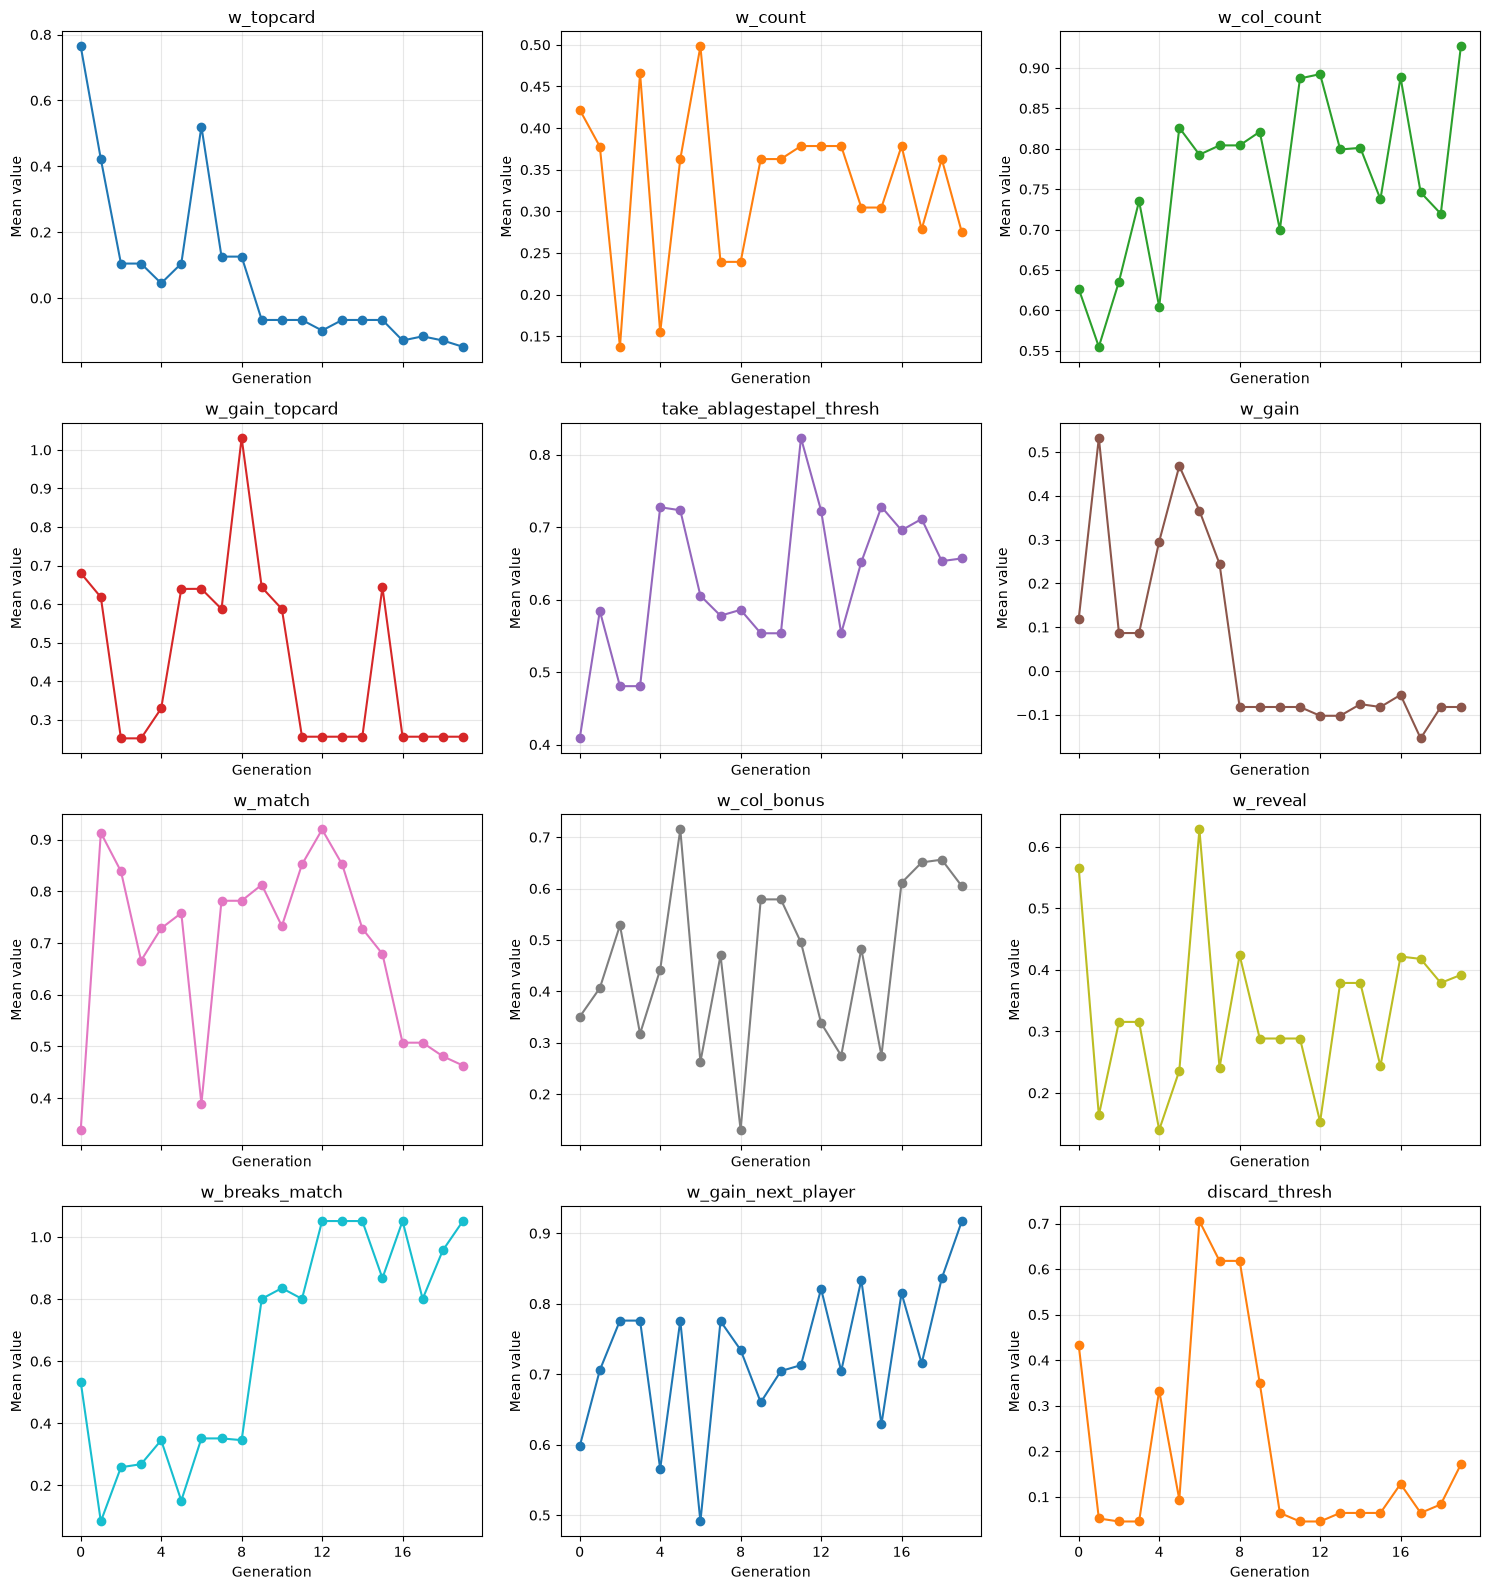

In [23]:
import math

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = genomes_df.drop(columns=["genome", "individuum"]).copy()
plot_df["generation"] = plot_df["generation"].astype(int)
generation_means = plot_df.groupby("generation").mean().sort_index()

ncols = 3
nrows = math.ceil(len(generation_means.columns) / ncols)
colors = sns.color_palette("tab10", len(generation_means.columns))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows), sharex=True)
axes = axes.flat

for ax, column in zip(axes, generation_means.columns):
    ax.plot(generation_means.index, generation_means[column], marker="o", color=colors.pop(0))
    ax.set_title(column)
    ax.set_xlabel("Generation")
    ax.set_ylabel("Mean value")
    ax.set_xticks(range(0, int(generation_means.index.max()) + 1, 4))
    ax.grid(True, alpha=0.3)

for ax in list(axes)[len(generation_means.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()